In [1]:
!pip install pandas numpy matplotlib scikit-learn statsmodels

In [2]:
import pandas as pd



In [5]:


df = pd.read_csv(r"C:\Users\MOUNIKA\Downloads\archive (14)\Sample - Superstore.csv", encoding='cp1252')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
# Convert Order Date to a real date
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')

# Remove duplicate rows
df = df.drop_duplicates()

# Check for missing values in important columns
print(df[['Order Date', 'Sales']].isnull().sum())

# Check the date range
print("From:", df['Order Date'].min(), "to", df['Order Date'].max())

Order Date    0
Sales         0
dtype: int64
From: 2014-01-03 00:00:00 to 2017-12-30 00:00:00


In [7]:
# Group all sales by month
monthly_sales = df.groupby(pd.Grouper(key='Order Date', freq='MS'))['Sales'].sum().reset_index()
monthly_sales.columns = ['Month', 'Sales']

print("Number of months:", len(monthly_sales))
monthly_sales.head()

Number of months: 48


,Month,Sales
0,2014-01-01,14236.895
1,2014-02-01,4519.892
2,2014-03-01,55691.009
3,2014-04-01,28295.345
4,2014-05-01,23648.287


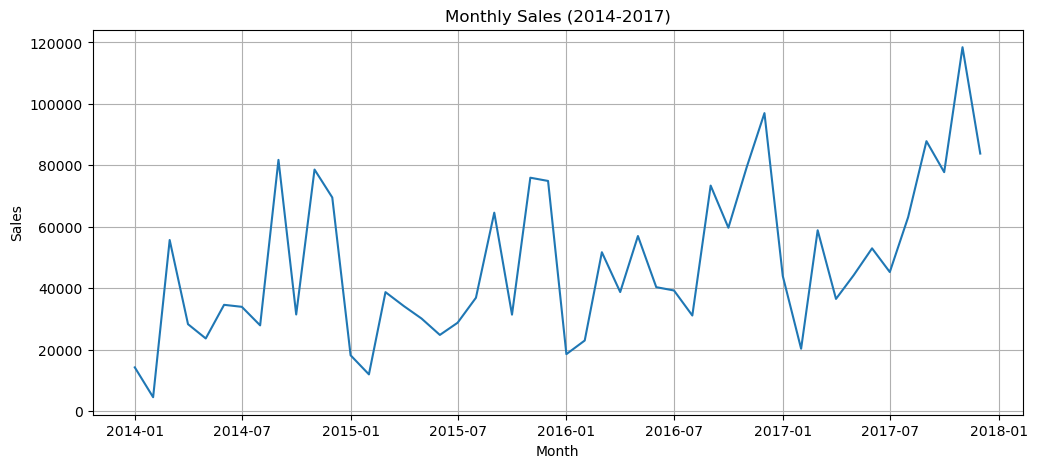

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(monthly_sales['Month'], monthly_sales['Sales'])
plt.title('Monthly Sales (2014-2017)')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid(True)
plt.show()

In [9]:
# Add helpful time features
monthly_sales['MonthNum'] = range(1, len(monthly_sales) + 1)  # 1, 2, 3... 48
monthly_sales['Month_of_Year'] = monthly_sales['Month'].dt.month  # 1-12, captures seasonality
monthly_sales['Year'] = monthly_sales['Month'].dt.year

monthly_sales.head()

,Month,Sales,MonthNum,Month_of_Year,Year
0,2014-01-01,14236.895,1,1,2014
1,2014-02-01,4519.892,2,2,2014
2,2014-03-01,55691.009,3,3,2014
3,2014-04-01,28295.345,4,4,2014
4,2014-05-01,23648.287,5,5,2014


In [10]:
from sklearn.ensemble import RandomForestRegressor

# Train on 2014-2016, test on 2017 (same split logic as a real forecast)
train = monthly_sales[monthly_sales['Year'] <= 2016]
test = monthly_sales[monthly_sales['Year'] == 2017]

features = ['MonthNum', 'Month_of_Year']
X_train, y_train = train[features], train['Sales']
X_test, y_test = test[features], test['Sales']

print("Train months:", len(train))
print("Test months:", len(test))

# Train a Random Forest model
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

# Predict on the test set (2017)
predictions = model.predict(X_test)

print("Done training and predicting.")

Train months: 36
Test months: 12
Done training and predicting.


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100

print(f"MAE  (Mean Absolute Error):      {mae:,.2f}")
print(f"RMSE (Root Mean Squared Error):  {rmse:,.2f}")
print(f"R² (R-squared):                  {r2:.3f}")
print(f"MAPE (Mean Absolute % Error):    {mape:.2f}%")


MAE  (Mean Absolute Error):      11,705.39
RMSE (Root Mean Squared Error):  13,954.15
R² (R-squared):                  0.707
MAPE (Mean Absolute % Error):    20.22%


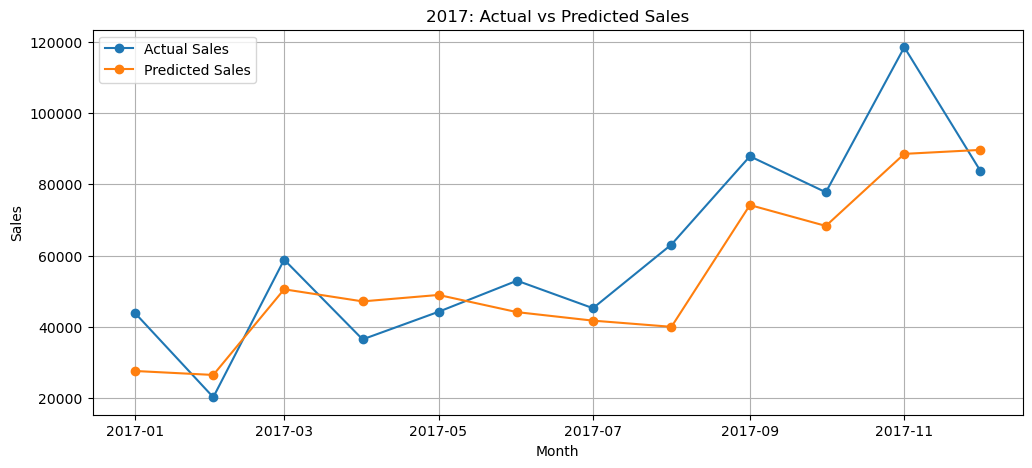

In [12]:
plt.figure(figsize=(12,5))
plt.plot(test['Month'], y_test.values, label='Actual Sales', marker='o')
plt.plot(test['Month'], predictions, label='Predicted Sales', marker='o')
plt.title('2017: Actual vs Predicted Sales')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
results = test[['Month']].copy()
results['Actual_Sales'] = y_test.values
results['Predicted_Sales'] = predictions
results['Error'] = results['Actual_Sales'] - results['Predicted_Sales']

results.to_csv('forecast_results.csv', index=False)
results

,Month,Actual_Sales,Predicted_Sales,Error
36,2017-01-01,43971.3740,27660.984079,16310.389921
37,2017-02-01,20301.1334,26547.010942,-6245.877542
38,2017-03-01,58872.3528,50566.353730,8305.999070
39,2017-04-01,36521.5361,47173.310028,-10651.773928
40,2017-05-01,44261.1102,48980.957204,-4719.847004
41,2017-06-01,52981.7257,44161.660889,8820.064811
42,2017-07-01,45264.4160,41777.543485,3486.872515
43,2017-08-01,63120.8880,40046.491727,23074.396273
44,2017-09-01,87866.6520,74192.328118,13674.323882
45,2017-10-01,77776.9232,68332.961213,9443.961987


## Model Evaluation Summary

**Model used:** Random Forest Regressor, trained on monthly sales from 2014–2016 and tested on 2017 (unseen data).

**Results:**
- MAE: ₹11,705 — on average, the forecast is off by about ₹11,705 per month
- RMSE: ₹13,954 — slightly higher than MAE, meaning a few months had larger errors
- R²: 0.71 — the model explains about 71% of the variation in monthly sales
- MAPE: 20.2% — the forecast is typically within about 20% of actual sales

**Business interpretation:**
The model captures the overall seasonal pattern (lower sales early in the year, rising toward the end), but it consistently underestimates the sharp November-December spike, missing it by roughly ₹20,000–30,000 in peak months. This means the forecast is reliable for general planning and budgeting, but during the holiday season a business should add a safety buffer of 20-25% above the model's prediction rather than relying on the raw number.

**Recommendation:** Use this forecast as a baseline for monthly planning, and increase safety stock by 20-25% in October-December to avoid stockouts during the peak sales period.
